In [5]:
import numpy as np
import pandas as pd

np.random.seed(42)

print('1. Génération des profils utilisateurs')
n_users = 100000

user_ids = [f'user_{i}' for i in range(1, n_users + 1)]

sources = ['Organic', 'Paid_Ads', 'Social_Media', 'Referral']
source_probabilities = [0.4, 0.3, 0.2, 0.1]
user_sources = np.random.choice(
    sources, size=n_users, p=source_probabilities
)

start_date = pd.to_datetime('2026-01-01')
install_dates = start_date + pd.to_timedelta(
    np.random.randint(0, 90, size=n_users), unit='d'
)

users_df = pd.DataFrame(
    {'user_id': user_ids, 'install_date': install_dates, 'source': user_sources}
)

print(f'-> {len(users_df):,} utilisateurs générés.')

print(
    '2. Génération des comportements et événements'
)

events_list = []


retention_profile = np.random.choice([0, 1, 2], size=n_users, p=[0.6, 0.25, 0.15])

for i, uid in enumerate(user_ids):
  i_date = install_dates[i]
  profile = retention_profile[i]

  events_list.append(
      {'user_id': uid, 'event_type': 'install', 'event_timestamp': i_date}
  )

  if profile == 0:
    continue
  elif profile == 1:
    s_date = i_date + pd.Timedelta(days=1, hours=np.random.randint(1, 12))
    events_list.append(
        {'user_id': uid, 'event_type': 'session', 'event_timestamp': s_date}
    )
  else:
    for day in range(1, np.random.randint(3, 15)):
      s_date = i_date + pd.Timedelta(
          days=day, hours=np.random.randint(0, 24)
      )
      events_list.append(
          {'user_id': uid, 'event_type': 'session', 'event_timestamp': s_date}
      )

      if np.random.rand() < 0.3:
        events_list.append(
            {
                'user_id': uid,
                'event_type': 'purchase',
                'event_timestamp': s_date + pd.Timedelta(minutes=5),
            }
        )

events_df = pd.DataFrame(events_list)

users_df.to_csv('users.csv', index=False)
events_df.to_csv('events.csv', index=False)

print(f'-> {len(events_df):,} événements générés')
print('Fichiers `users.csv` et `events.csv` enregistrés.')

1. Génération des profils utilisateurs
-> 100,000 utilisateurs générés.
2. Génération des comportements et événements
-> 272,672 événements générés
Fichiers `users.csv` et `events.csv` enregistrés.


1. Chargement des données
2. Fusion des tables d'utilisateurs et d'événements
3. Calcul de la matrice de rétention

 Matrice de rétention
cohort_index      0    1
cohort_month            
2026-01       100.0  4.5
2026-02       100.0  5.1
2026-03       100.0  4.4


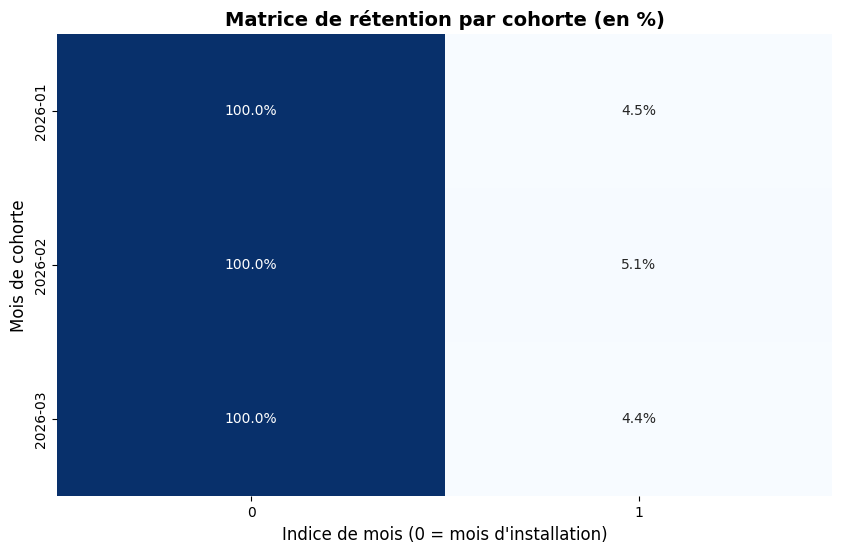

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print('1. Chargement des données')
users_df = pd.read_csv('users.csv')
events_df = pd.read_csv('events.csv')

users_df['install_date'] = pd.to_datetime(users_df['install_date'])
events_df['event_timestamp'] = pd.to_datetime(events_df['event_timestamp'])

print("2. Fusion des tables d'utilisateurs et d'événements")
df = pd.merge(events_df, users_df, on='user_id', how='inner')

df['cohort_month'] = df['install_date'].dt.to_period('M')
df['event_month'] = df['event_timestamp'].dt.to_period('M')

df['cohort_index'] = (
    df['event_month'].astype('int') - df['cohort_month'].astype('int')
)

print('3. Calcul de la matrice de rétention')
cohort_data = (
    df.groupby(['cohort_month', 'cohort_index'])['user_id']
    .nunique()
    .reset_index()
)
cohort_pivot = cohort_data.pivot(
    index='cohort_month', columns='cohort_index', values='user_id'
)

cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0)

print('\n Matrice de rétention')
print(retention_matrix.round(3) * 100)

plt.figure(figsize=(10, 6))
sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1%',
    cmap='Blues',
    cbar=False,
)
plt.title(
    'Matrice de rétention par cohorte (en %)', fontsize=14, fontweight='bold'
)
plt.xlabel("Indice de mois (0 = mois d'installation)", fontsize=12)
plt.ylabel("Mois de cohorte", fontsize=12)
plt.show()

Aperçu des données de survie prêtes pour le modèle:
  user_id        source  age_days  churned
0  user_1       Organic         0     True
1  user_2      Referral         7     True
2  user_3  Social_Media         0     True
3  user_4      Paid_Ads         1     True
4  user_5       Organic         0     True


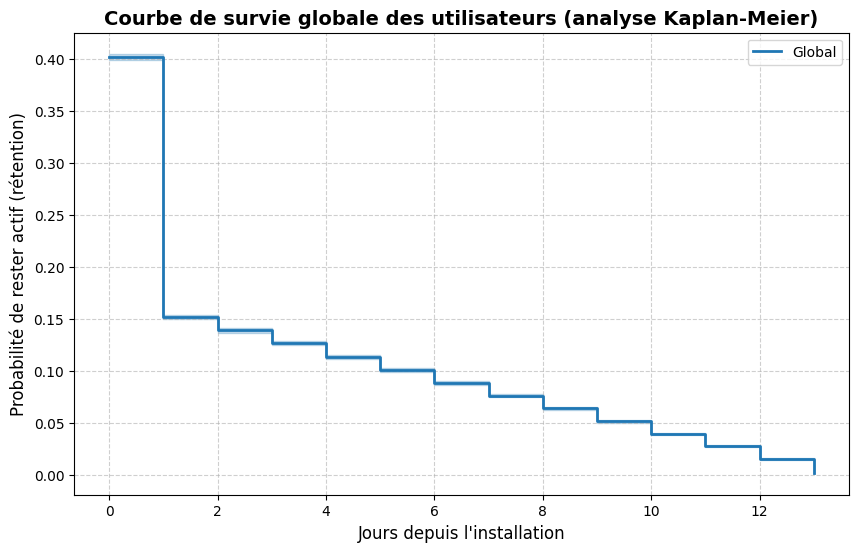

In [9]:
!pip install lifelines
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt
import pandas as pd

users_df = pd.read_csv('users.csv')
events_df = pd.read_csv('events.csv')

users_df['install_date'] = pd.to_datetime(users_df['install_date'])
events_df['event_timestamp'] = pd.to_datetime(events_df['event_timestamp'])

last_activity = (
    events_df.groupby('user_id')['event_timestamp'].max().reset_index()
)
user_survival = pd.merge(users_df, last_activity, on='user_id')

max_date = events_df['event_timestamp'].max()

user_survival['age_days'] = (
    user_survival['event_timestamp'] - user_survival['install_date']
).dt.days

user_survival['churned'] = (
    max_date - user_survival['event_timestamp']
).dt.days > 7

print("Aperçu des données de survie prêtes pour le modèle:")
print(user_survival[['user_id', 'source', 'age_days', 'churned']].head())

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

durations = user_survival['age_days']
event_observed = user_survival[
    'churned'
]

kmf.fit(durations=durations, event_observed=event_observed, label='Global')
kmf.plot_survival_function(ci_show=True, linewidth=2)

plt.title(
    "Courbe de survie globale des utilisateurs (analyse Kaplan-Meier)",
    fontsize=14,
    fontweight='bold',
)
plt.xlabel("Jours depuis l'installation", fontsize=12)
plt.ylabel("Probabilité de rester actif (rétention)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Répartition des segments utilisateurs
                  Segment  Percentage
0  Churned / Install-only      59.844
1            Casual Users      27.497
2             Power Users      12.659


/tmp/ipykernel_2667/3745826156.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_counts, x='Segment', y='Percentage', palette='viridis')


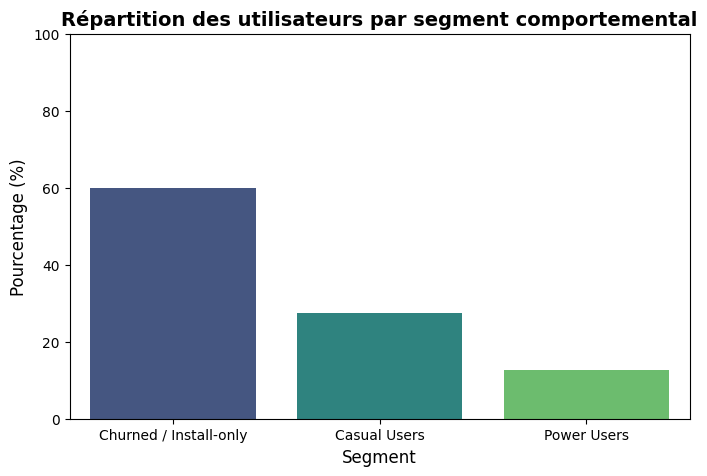

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

users_df = pd.read_csv('users.csv')
events_df = pd.read_csv('events.csv')

user_activity = (
    events_df.groupby(['user_id', 'event_type']).size().unstack(fill_value=0)
)

for col in ['install', 'session', 'purchase', 'uninstall']:
  if col not in user_activity.columns:
    user_activity[col] = 0

user_activity = user_activity.reset_index()

segment_df = pd.merge(users_df, user_activity, on='user_id')

def assign_segment(row):
  if row['session'] > 3:
    return 'Power Users'
  elif row['session'] >= 1:
    return 'Casual Users'
  else:
    return 'Churned / Install-only'


segment_df['segment'] = segment_df.apply(assign_segment, axis=1)

segment_counts = (
    segment_df['segment'].value_counts(normalize=True) * 100
).reset_index()
segment_counts.columns = ['Segment', 'Percentage']

print('Répartition des segments utilisateurs')
print(segment_counts)

plt.figure(figsize=(8, 5))
sns.barplot(data=segment_counts, x='Segment', y='Percentage', palette='viridis')
plt.title(
    'Répartition des utilisateurs par segment comportemental',
    fontsize=14,
    fontweight='bold',
)
plt.ylabel('Pourcentage (%)', fontsize=12)
plt.xlabel('Segment', fontsize=12)
plt.ylim(0, 100)
plt.show()

Répartition des segments par source d’acquisition
segment       Casual Users  Churned / Install-only  Power Users
source                                                         
Organic               27.3                    59.9         12.8
Paid_Ads              27.3                    60.5         12.2
Referral              28.1                    58.9         13.0
Social_Media          28.0                    59.2         12.8


<Figure size 1000x600 with 0 Axes>

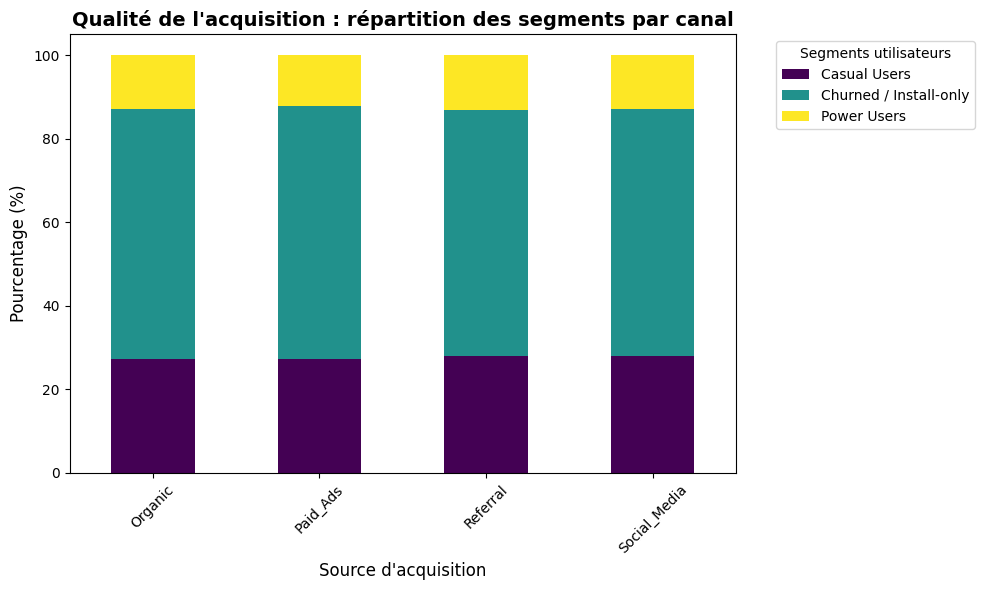

In [18]:
source_segment_analysis = (
    pd.crosstab(segment_df['source'], segment_df['segment'], normalize='index')
    * 100
)

print(
    'Répartition des segments par source d’acquisition'
)
print(source_segment_analysis.round(1))

plt.figure(figsize=(10, 6))
source_segment_analysis.plot(
    kind='bar', stacked=True, colormap='viridis', figsize=(10, 6)
)
plt.title(
    "Qualité de l'acquisition : répartition des segments par canal",
    fontsize=14,
    fontweight='bold',
)
plt.xlabel("Source d'acquisition", fontsize=12)
plt.ylabel('Pourcentage (%)', fontsize=12)
plt.legend(title='Segments utilisateurs', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()